<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Finding Correlation**


Estimated time needed: **30** minutes


In this lab, you will work with a cleaned dataset to perform exploratory data analysis (EDA). You will examine the distribution of the data, identify outliers, and determine the correlation between different columns in the dataset.


## Objectives


In this lab, you will perform the following:


- Identify the distribution of compensation data in the dataset.

- Remove outliers to refine the dataset.

- Identify correlations between various features in the dataset.


## Hands on Lab


##### Step 1: Install and Import Required Libraries


In [2]:
# Install the necessary libraries
!pip install pandas
!pip install matplotlib
!pip install seaborn

# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 82.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 170.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pandas]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 725.3 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 737.6 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 784.7 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 634.5 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]


### Step 2: Load the Dataset


In [3]:
# Load the dataset from the given URL
file_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv"
df = pd.read_csv(file_url)

# Display the first few rows to understand the structure of the dataset
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


<h3>Step 3: Analyze and Visualize Compensation Distribution</h3>


**Task**: Plot the distribution and histogram for `ConvertedCompYearly` to examine the spread of yearly compensation among respondents.


Respondents with compensation data: 23435
99th percentile: 393751.06
count    2.343500e+04
mean     8.615529e+04
std      1.867570e+05
min      1.000000e+00
25%      3.271200e+04
50%      6.500000e+04
75%      1.079715e+05
max      1.625660e+07
Name: ConvertedCompYearly, dtype: float64

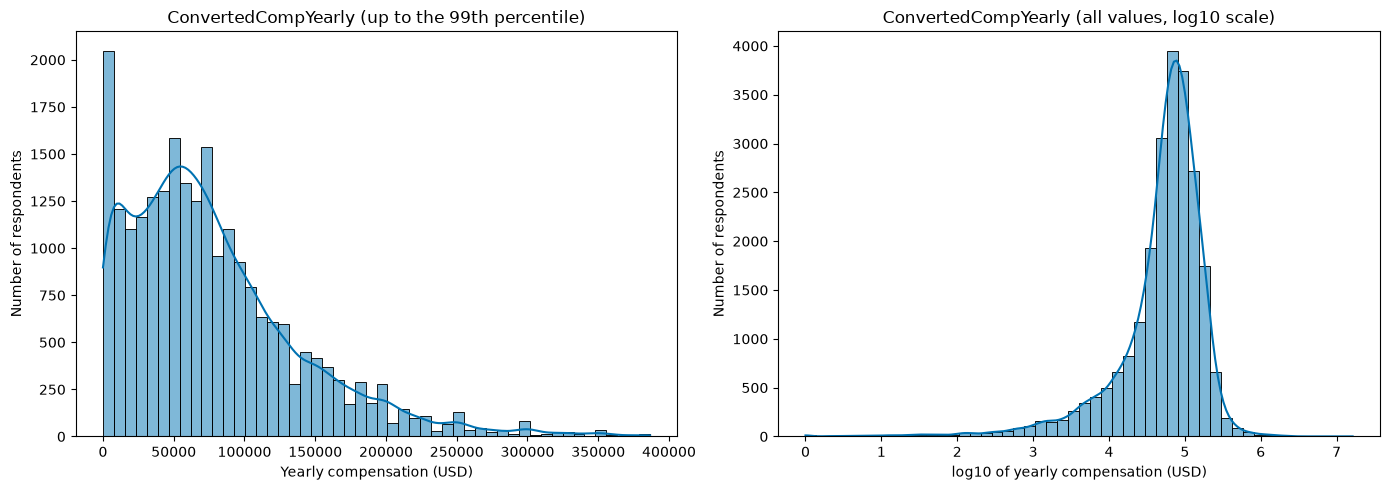

In [4]:
## Write your code here
# Step 3: Distribution and histogram of ConvertedCompYearly
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

comp = df["ConvertedCompYearly"].dropna()
p99 = comp.quantile(0.99)

print("Respondents with compensation data:", comp.shape[0])
print("99th percentile:", round(p99, 2))
print(comp.describe())
# Histogram with distribution curve: (left) up to the 99th percentile, (right) all values on a log scale
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(comp[comp <= p99], bins=50, kde=True, color="#0072B2", ax=axes[0])
axes[0].set_title("ConvertedCompYearly (up to the 99th percentile)")
axes[0].set_xlabel("Yearly compensation (USD)")
axes[0].set_ylabel("Number of respondents")

sns.histplot(np.log10(comp), bins=50, kde=True, color="#0072B2", ax=axes[1])
axes[1].set_title("ConvertedCompYearly (all values, log10 scale)")
axes[1].set_xlabel("log10 of yearly compensation (USD)")
axes[1].set_ylabel("Number of respondents")

plt.tight_layout()
plt.show()

<h3>Step 4: Calculate Median Compensation for Full-Time Employees</h3>


**Task**: Filter the data to calculate the median compensation for respondents whose employment status is "Employed, full-time."


In [5]:
## Write your code here
# Step 4: Median compensation for full-time employees
full_time = df[df["Employment"] == "Employed, full-time"]

print("Full-time employees:", full_time.shape[0])
print("With compensation data:", full_time["ConvertedCompYearly"].notna().sum())

median_full_time = full_time["ConvertedCompYearly"].median()
print("Median compensation (Employed, full-time):", median_full_time)
# Compare with everyone else
overall_median = df["ConvertedCompYearly"].median()
print("Overall median compensation:", overall_median)

Full-time employees: 39041
With compensation data: 17586
Median compensation (Employed, full-time): 69814.0
Overall median compensation: 65000.0

<h3>Step 5: Analyzing Compensation Range and Distribution by Country</h3>


Explore the range of compensation in the ConvertedCompYearly column by analyzing differences across countries. Use box plots to compare the compensation distributions for each country to identify variations and anomalies within each region, providing insights into global compensation trends.



Country
USA            4677
Germany        2046
Ukraine        1474
UK             1391
India          1037
France          918
Canada          871
Brazil          685
Poland          586
Netherlands     561
Name: count, dtype: int64
              count       25%       50%       75%        max
Country                                                     
USA          4677.0  101000.0  143000.0  190000.0  1900000.0
Canada        871.0   65424.0   87231.0  116309.0  1562898.0
UK           1391.0   58598.0   84076.0  121018.0  1273879.0
Germany      2046.0   53703.0   73036.0   91295.0  1288874.0
Netherlands   561.0   52788.0   69814.0   96666.0   537031.0
Poland        586.0   29696.0   55536.0   81663.0  1000000.0
France        918.0   42962.0   53703.0   75184.0   644437.0
Ukraine      1474.0    3194.0   26904.0   55959.0  4936778.0
Brazil        685.0   13054.0   23945.0   44757.0  6340564.0
India        1037.0    7178.0   16749.0   34694.0  3367716.0

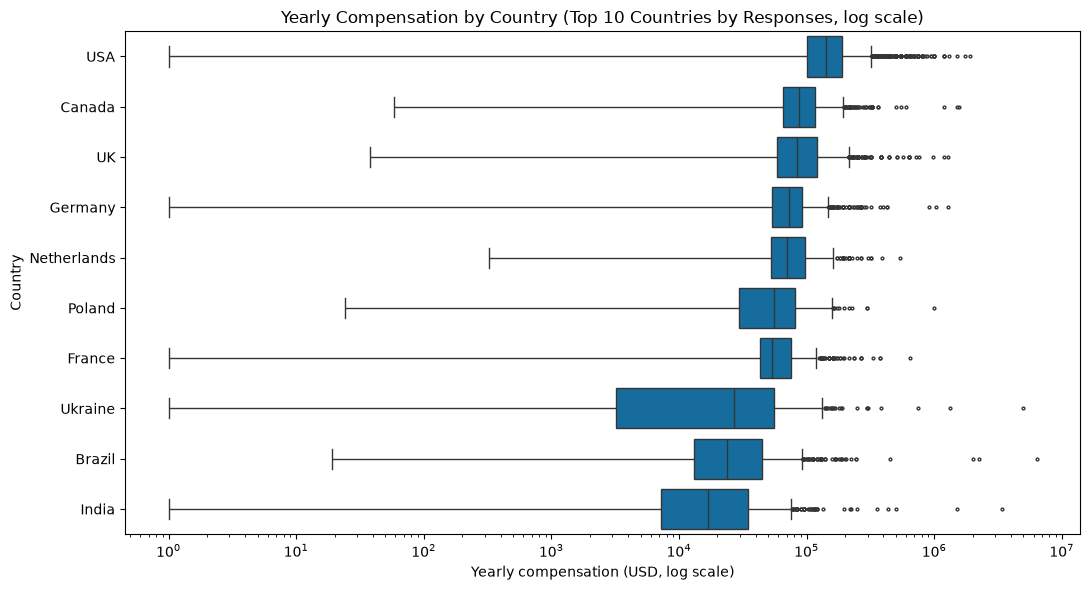

In [6]:
## Write your code here
# Step 5: Pick the top 10 countries by number of respondents with compensation data
comp_df = df[["Country", "ConvertedCompYearly"]].dropna().copy()
comp_df["Country"] = comp_df["Country"].replace({
    "United States of America": "USA",
    "United Kingdom of Great Britain and Northern Ireland": "UK"
})

top_countries = comp_df["Country"].value_counts().head(10).index
comp_top = comp_df[comp_df["Country"].isin(top_countries)]
print(comp_df["Country"].value_counts().head(10))
# Summary of compensation by country (median, quartiles, max)
summary = comp_top.groupby("Country")["ConvertedCompYearly"].describe()[["count", "25%", "50%", "75%", "max"]]
print(summary.sort_values("50%", ascending=False).round(0))
# Box plots comparing compensation distributions by country (log scale)

order = comp_top.groupby("Country")["ConvertedCompYearly"].median().sort_values(ascending=False).index

plt.figure(figsize=(11, 6))
sns.boxplot(data=comp_top, x="ConvertedCompYearly", y="Country", order=order,
            color="#0072B2", fliersize=2)
plt.xscale("log")
plt.title("Yearly Compensation by Country (Top 10 Countries by Responses, log scale)")
plt.xlabel("Yearly compensation (USD, log scale)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

<h3>Step 6: Removing Outliers from the Dataset</h3>


**Task**: Create a new DataFrame by removing outliers from the `ConvertedCompYearly` column to get a refined dataset for correlation analysis.


In [7]:
## Write your code here
# Step 6: Remove outliers from ConvertedCompYearly using the IQR method
q1 = df["ConvertedCompYearly"].quantile(0.25)
q3 = df["ConvertedCompYearly"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

# Keep rows within the bounds; rows with missing compensation are kept (a missing value is not an outlier)
is_outlier = (df["ConvertedCompYearly"] < lower_bound) | (df["ConvertedCompYearly"] > upper_bound)
df_clean = df[~is_outlier].copy()
# Validate the new DataFrame
print("Original shape:", df.shape)
print("New shape:", df_clean.shape)
print("Rows removed:", df.shape[0] - df_clean.shape[0])
print("Max ConvertedCompYearly now:", df_clean["ConvertedCompYearly"].max())
print("Mean ConvertedCompYearly now:", round(df_clean["ConvertedCompYearly"].mean(), 2))
print("Median ConvertedCompYearly now:", df_clean["ConvertedCompYearly"].median())

Lower bound: -80177.25
Upper bound: 220860.75Original shape: (65437, 114)
New shape: (64459, 114)
Rows removed: 978
Max ConvertedCompYearly now: 220207.0
Mean ConvertedCompYearly now: 71347.2
Median ConvertedCompYearly now: 63694.0

<h3>Step 7: Finding Correlations Between Key Variables</h3>


**Task**: Calculate correlations between `ConvertedCompYearly`, `WorkExp`, and `JobSatPoints_1`. Visualize these correlations with a heatmap.


                     ConvertedCompYearly  WorkExp  JobSatPoints_1
ConvertedCompYearly                1.000    0.408          -0.058
WorkExp                            0.408    1.000          -0.028
JobSatPoints_1                    -0.058   -0.028           1.000

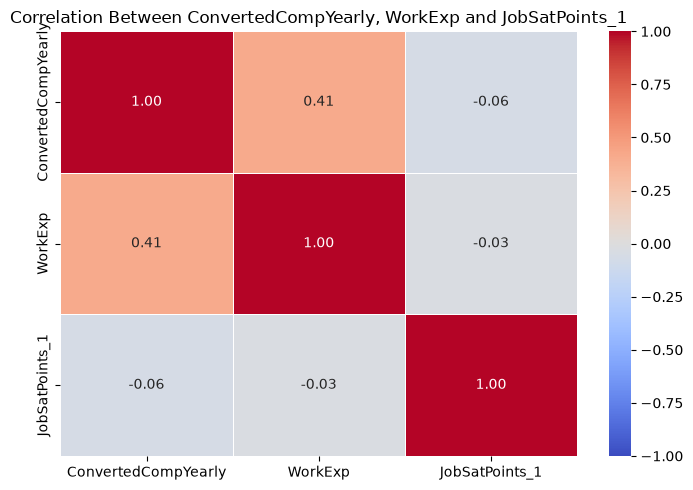

In [10]:
## Write your code here
# Step 7: Correlations between key variables (using the outlier-free df_clean)
cols = ["ConvertedCompYearly", "WorkExp", "JobSatPoints_1"]
corr_matrix = df_clean[cols].corr()
print(corr_matrix.round(3))

plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Between ConvertedCompYearly, WorkExp and JobSatPoints_1")
plt.tight_layout()
plt.show()

<h3>Step 8: Scatter Plot for Correlations</h3>


**Task**: Create scatter plots to examine specific correlations between `ConvertedCompYearly` and `WorkExp`, as well as between `ConvertedCompYearly` and `JobSatPoints_1`.


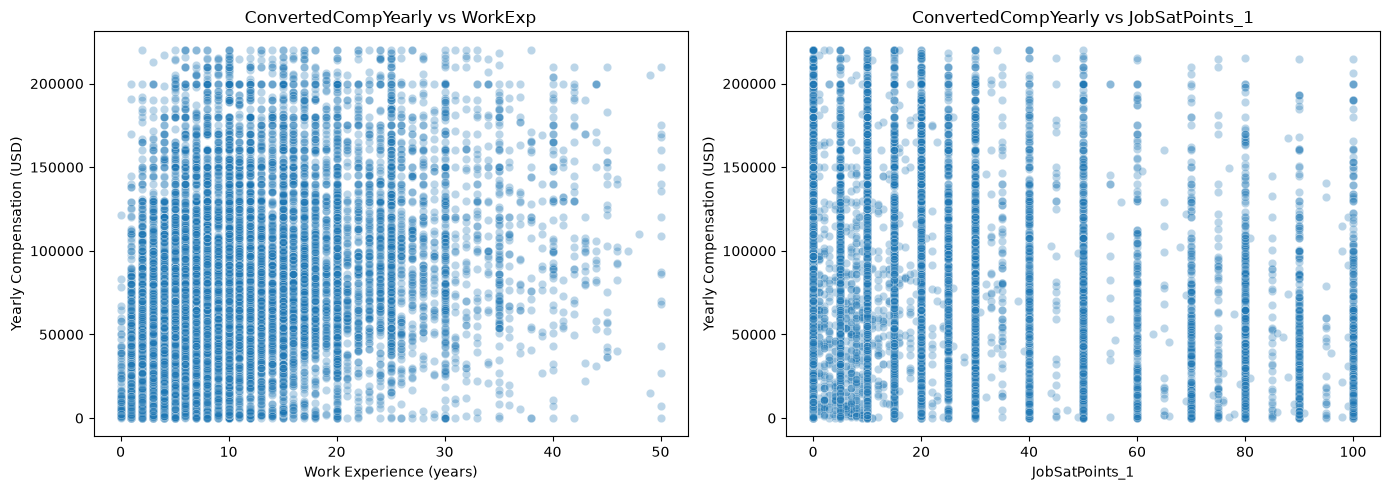

In [11]:
## Write your code here
# Step 8: Scatter plots for specific correlations (using df_clean)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: ConvertedCompYearly vs WorkExp
sns.scatterplot(data=df_clean, x="WorkExp", y="ConvertedCompYearly", alpha=0.3, ax=axes[0])
axes[0].set_title("ConvertedCompYearly vs WorkExp")
axes[0].set_xlabel("Work Experience (years)")
axes[0].set_ylabel("Yearly Compensation (USD)")

# Plot 2: ConvertedCompYearly vs JobSatPoints_1
sns.scatterplot(data=df_clean, x="JobSatPoints_1", y="ConvertedCompYearly", alpha=0.3, ax=axes[1])
axes[1].set_title("ConvertedCompYearly vs JobSatPoints_1")
axes[1].set_xlabel("JobSatPoints_1")
axes[1].set_ylabel("Yearly Compensation (USD)")

plt.tight_layout()
plt.show()

<h3>Summary</h3>


In this lab, you practiced essential skills in correlation analysis by:

- Examining the distribution of yearly compensation with histograms and box plots.
- Detecting and removing outliers from compensation data.
- Calculating correlations between key variables such as compensation, work experience, and job satisfaction.
- Visualizing relationships with scatter plots and heatmaps to gain insights into the associations between these features.

By following these steps, you have developed a solid foundation for analyzing relationships within the dataset.


## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


Copyright © IBM Corporation. All rights reserved.
